# Task 4 — Exploring the Netflix catalogue

We’ll look at the titles in this dataset: what formats and genres appear, where titles are credited, and how release and platform-addition dates vary. This is a catalogue analysis, not a measure of what viewers watched or preferred.

Run the notebook with `task4_netflix/` as the working folder. It reads the source CSV from `../data/raw/`.

In [2]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
RAW = Path("../data/raw/netflix_titles.csv")
OUT = Path("../data/processed")
FIG = Path("figures")
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()

## 1. Get familiar with the data and clean it

In [3]:
df = pd.read_csv(RAW)
print("Shape:", df.shape)
df.head()

Shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [5]:
missing = pd.DataFrame({"missing": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)})
missing[missing["missing"] > 0].sort_values("missing", ascending=False)

,missing,pct
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03


In [6]:
d = df.copy()

# 1.1 date_added -> datetime (raw strings contain leading spaces, e.g. " September 9, 2019")
d["date_added"] = pd.to_datetime(d["date_added"].str.strip(), errors="coerce")
d["year_added"] = d["date_added"].dt.year
d["month_added"] = d["date_added"].dt.month_name()

# 1.2 Fill missing categorical text
d["director"] = d["director"].fillna("Unknown")
d["cast"] = d["cast"].fillna("Unknown")
d["country"] = d["country"].fillna("Unknown")
d["rating"] = d["rating"].fillna(d["rating"].mode()[0])
d = d.dropna(subset=["duration"]) if d["duration"].isna().any() else d

# 1.3 New features: release_decade, is_movie
d["release_decade"] = (d["release_year"] // 10 * 10).astype(int).astype(str) + "s"
d["is_movie"] = (d["type"] == "Movie").astype(int)

# 1.4 Parse duration: minutes for movies, seasons for TV shows
d["duration_value"] = d["duration"].str.extract(r"(\d+)").astype(float)
d["duration_minutes"] = np.where(d["is_movie"] == 1, d["duration_value"], np.nan)
d["seasons"] = np.where(d["is_movie"] == 0, d["duration_value"], np.nan)

print("Rows with unparseable date_added (kept as NaT):", d["date_added"].isna().sum())
d[["type", "date_added", "year_added", "release_decade", "is_movie", "duration_minutes", "seasons"]].head()

Rows with unparseable date_added (kept as NaT): 10


,type,date_added,year_added,release_decade,is_movie,duration_minutes,seasons
0,Movie,2021-09-25,2021.0,2020s,1,90.0,NaN
1,TV Show,2021-09-24,2021.0,2020s,0,NaN,2.0
2,TV Show,2021-09-24,2021.0,2020s,0,NaN,1.0
3,TV Show,2021-09-24,2021.0,2020s,0,NaN,1.0
4,TV Show,2021-09-24,2021.0,2020s,0,NaN,2.0


## 2. Prepare country and genre fields

A title can list more than one country or genre. We’ll split and expand those fields so each credit can be counted, keeping in mind that a title may appear in several groups.

In [7]:
d["release_year"] = d["release_year"].astype(int)
d["content_type"] = d["type"]  # Movie / TV Show

split = lambda s: [x.strip() for x in str(s).split(",") if x.strip()]
d["country_list"] = d["country"].apply(split)
d["genre_list"] = d["listed_in"].apply(split)
d["primary_country"] = d["country_list"].str[0]

countries_exploded = d.explode("country_list")
countries_known = countries_exploded[countries_exploded["country_list"] != "Unknown"]
country_counts = countries_known["country_list"].value_counts()
top5_countries = country_counts.head(5).index.tolist()
d["is_top5_country"] = d["country_list"].apply(lambda lst: int(any(c in top5_countries for c in lst)))

genres_exploded = d.explode("genre_list")
genre_counts = genres_exploded["genre_list"].value_counts()

print("Top 5 countries:\n", country_counts.head(5), "\n")
print("Top 10 genres:\n", genre_counts.head(10))

Top 5 countries:
 country_list
United States     3687
India             1046
United Kingdom     806
Canada             445
France             393
Name: count, dtype: int64 

Top 10 genres:
 genre_list
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


## 3. Explore the catalogue

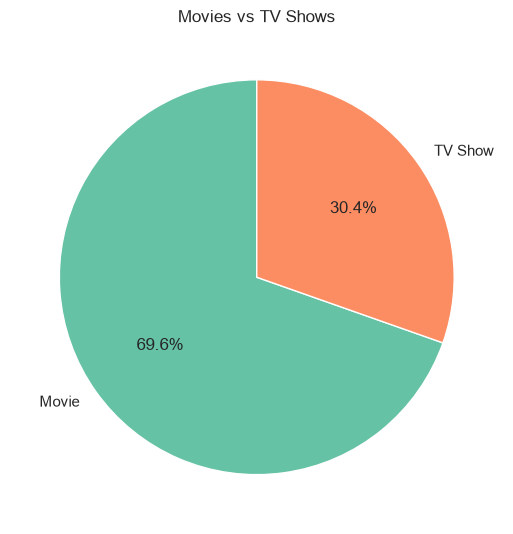

In [8]:
# 3.1 Pie chart - Movies vs TV Shows
type_counts = d["content_type"].value_counts()
plt.figure(figsize=(5.5, 5.5))
plt.pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("Set2")[:2], wedgeprops={"edgecolor": "white"})
plt.title("Movies vs TV Shows")
savefig("01_movies_vs_tv_pie.png")

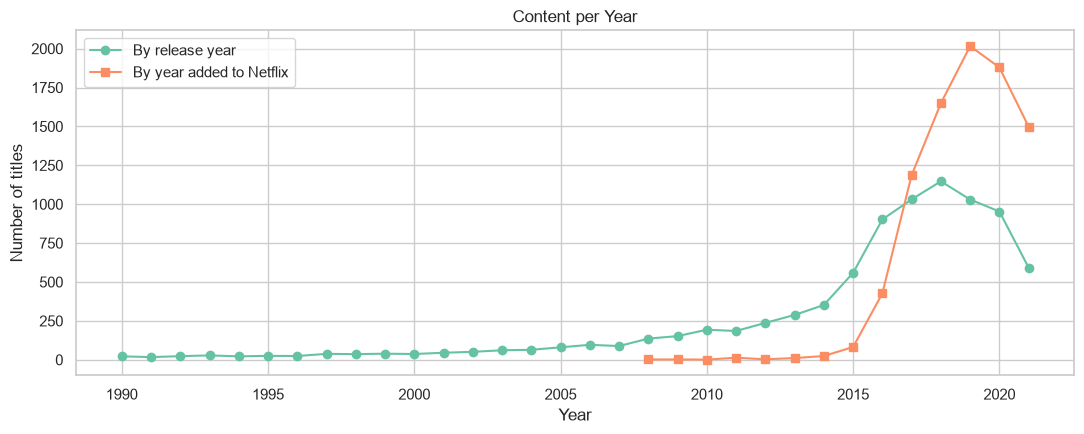

In [9]:
# 3.2 Line plot - content released per year (+ content added per year)
rel = d.groupby("release_year").size()
added = d.groupby("year_added").size()
plt.figure(figsize=(11, 4.5))
rel[rel.index >= 1990].plot(marker="o", label="By release year")
added.plot(marker="s", label="By year added to Netflix")
plt.xlabel("Year"); plt.ylabel("Number of titles"); plt.legend()
plt.title("Content per Year")
savefig("02_content_per_year.png")

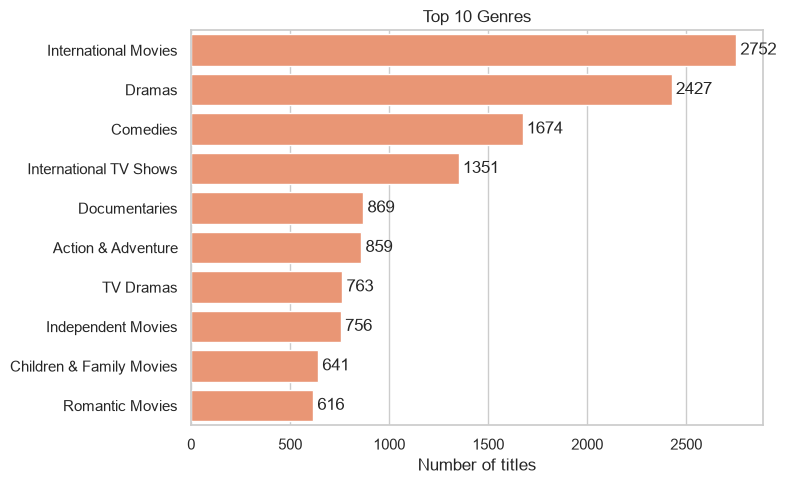

In [10]:
# 3.3 Barplot - Top 10 genres
top_genres = genre_counts.head(10)
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=top_genres.values, y=top_genres.index, color=sns.color_palette("Set2")[1])
ax.bar_label(ax.containers[0], padding=3)
plt.xlabel("Number of titles"); plt.ylabel("")
plt.title("Top 10 Genres")
savefig("03_top10_genres.png")

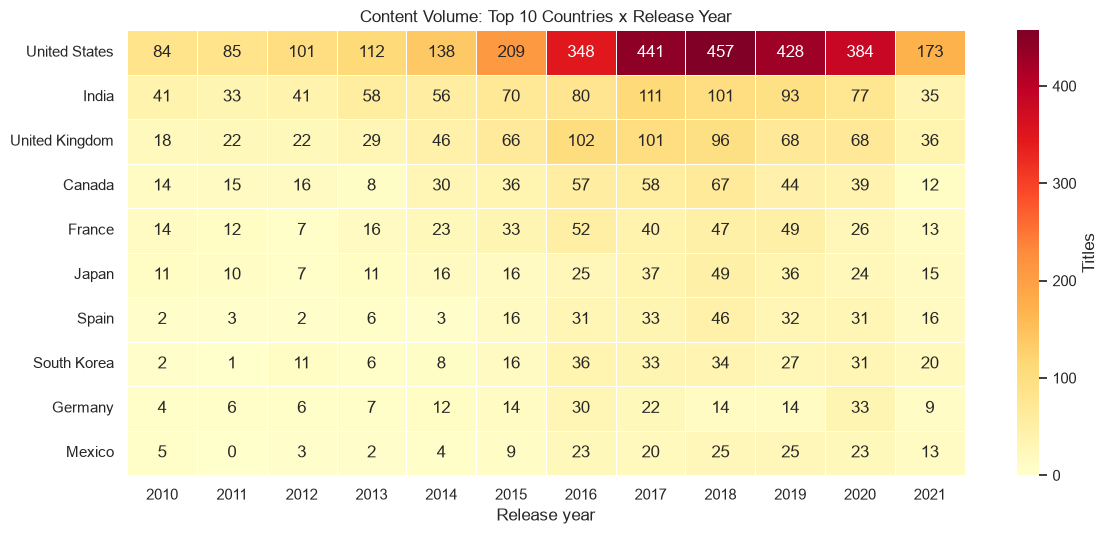

In [11]:
# 3.4 Heatmap - Country vs content volume (top 10 countries x release year since 2010)
top10_countries = country_counts.head(10).index
recent = countries_known[(countries_known["country_list"].isin(top10_countries)) & (countries_known["release_year"] >= 2010)]
pivot = recent.pivot_table(index="country_list", columns="release_year", values="show_id", aggfunc="count", fill_value=0)
pivot = pivot.loc[top10_countries]
plt.figure(figsize=(12, 5.5))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt="d", linewidths=.5, cbar_kws={"label": "Titles"})
plt.xlabel("Release year"); plt.ylabel("")
plt.title("Content Volume: Top 10 Countries x Release Year")
savefig("04_country_year_heatmap.png")

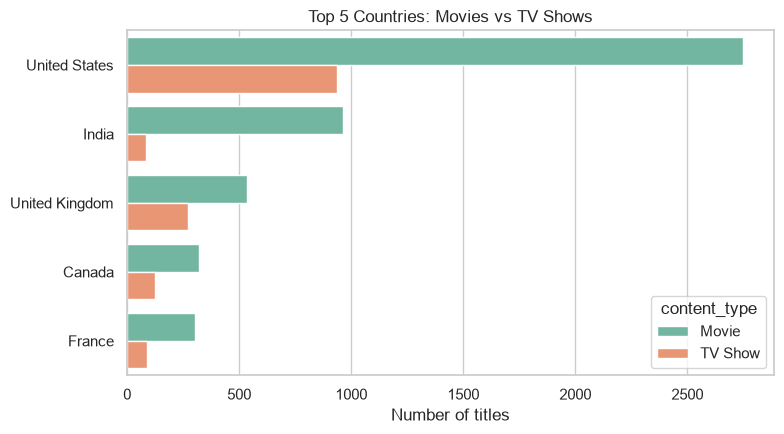

In [12]:
# 3.5 Top 5 countries split by content type
c5 = countries_known[countries_known["country_list"].isin(top5_countries)]
plt.figure(figsize=(8, 4.5))
sns.countplot(data=c5, y="country_list", hue="content_type", order=top5_countries)
plt.xlabel("Number of titles"); plt.ylabel("")
plt.title("Top 5 Countries: Movies vs TV Shows")
savefig("05_top5_countries_by_type.png")

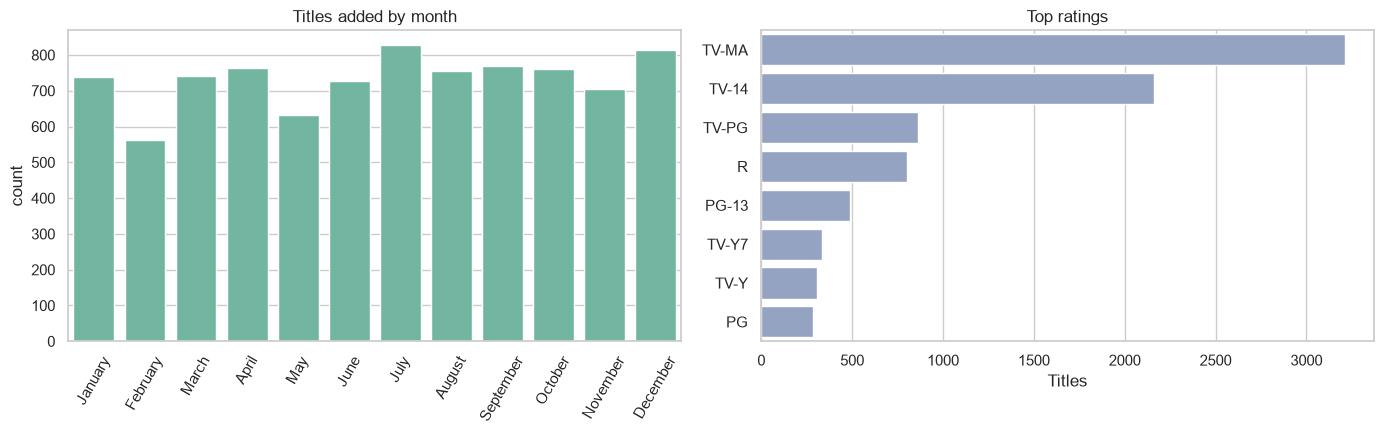

In [13]:
# 3.6 Titles added per month - best time of year? (and rating mix)
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.countplot(data=d.dropna(subset=["month_added"]), x="month_added", order=month_order, ax=axes[0])
axes[0].tick_params(axis="x", rotation=60); axes[0].set_title("Titles added by month"); axes[0].set_xlabel("")
rate_counts = d["rating"].value_counts().head(8)
sns.barplot(x=rate_counts.values, y=rate_counts.index, ax=axes[1], color=sns.color_palette("Set2")[2])
axes[1].set_title("Top ratings"); axes[1].set_xlabel("Titles"); axes[1].set_ylabel("")
savefig("06_month_and_rating.png")

## 4. A simple trend estimate

We’ll fit a straight-line trend to recent release-year counts and extend it two years ahead. The latest year is usually incomplete, so we leave it out of the fit. Treat the results as a rough illustration, not a dependable forecast.

Trained on 2013-2020 | slope = +118.3 titles/year | R2 = 0.75
  Forecast 2022: ~1433 titles
  Forecast 2023: ~1552 titles


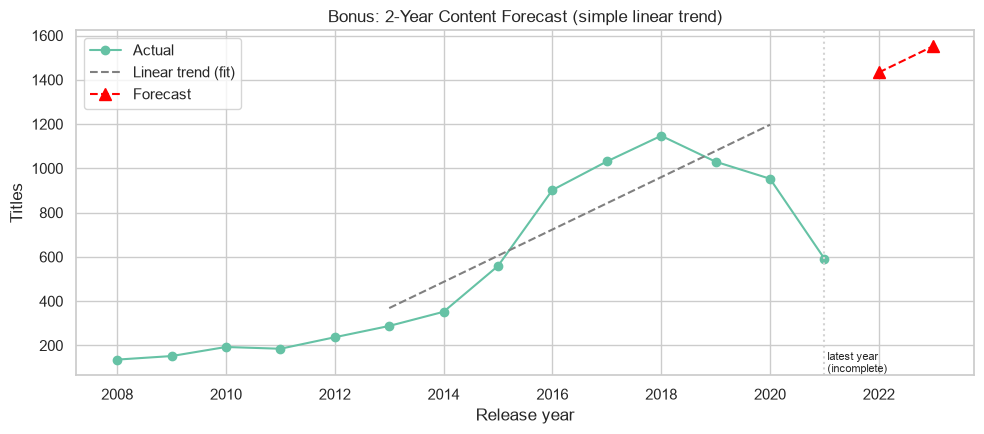

In [14]:
max_year = int(d["release_year"].max())
last_complete = max_year - 1
train = rel[(rel.index >= last_complete - 7) & (rel.index <= last_complete)]   # 8 most recent complete years
coef = np.polyfit(train.index, train.values, deg=1)
future_years = np.array([max_year + 1, max_year + 2])
pred = np.clip(np.polyval(coef, future_years), 0, None).round().astype(int)
fitted = np.polyval(coef, train.index)
r2 = 1 - ((train.values - fitted) ** 2).sum() / ((train.values - train.values.mean()) ** 2).sum()

print(f"Trained on {train.index.min()}-{train.index.max()} | slope = {coef[0]:+.1f} titles/year | R2 = {r2:.2f}")
for y, p in zip(future_years, pred):
    print(f"  Forecast {y}: ~{p} titles")

plt.figure(figsize=(10, 4.5))
plt.plot(rel[rel.index >= last_complete - 12].index, rel[rel.index >= last_complete - 12].values, marker="o", label="Actual")
plt.plot(train.index, fitted, "--", color="gray", label="Linear trend (fit)")
plt.plot(future_years, pred, "r^--", markersize=9, label="Forecast")
plt.axvline(max_year, color="lightgray", ls=":"); plt.text(max_year, plt.ylim()[0], " latest year\n (incomplete)", fontsize=8, va="bottom")
plt.xlabel("Release year"); plt.ylabel("Titles"); plt.legend()
plt.title("Bonus: 2-Year Content Forecast (simple linear trend)")
savefig("07_forecast.png")

## 5. Pull the findings together

In [15]:
movie_pct = type_counts.get("Movie", 0) / len(d) * 100
peak_year = int(rel.idxmax())
peak_add_year = int(added.idxmax())
top_c, top_c_n = country_counts.index[0], country_counts.iloc[0]
top_g, top_g_n = genre_counts.index[0], genre_counts.iloc[0]
recent_share = (d["release_year"] >= 2015).mean() * 100
unknown_dir = (d["director"] == "Unknown").mean() * 100

insights = [
    ("The catalogue has more movies than TV shows",
     f"Movies are {movie_pct:.1f}% of titles and TV shows {100 - movie_pct:.1f}%.",
     "This describes the catalogue mix, not which format viewers prefer or which one brings them back to the service."),
    ("Many titles were released recently",
     f"{recent_share:.1f}% of titles were released in 2015 or later; release volume peaks in {peak_year}, "
     f"and additions to the platform peak in {peak_add_year}.",
     "A title's release year and its platform-addition year tell different stories. Looking at both helps show how old the content was when it appeared in this catalogue."),
    (f"{top_c} has the most country credits",
     f"{top_c} is listed for {top_c_n:,} titles; the five most frequently listed countries are {', '.join(top5_countries)}.",
     "Country credits can overlap because a title may list several countries. The counts describe credits in this dataset, rather than exclusive production shares."),
    (f"'{top_g}' is the most common genre label",
     f"{top_g} appears {top_g_n:,} times; the three most common labels are {', '.join(genre_counts.head(3).index)}.",
     "Titles can have multiple genre labels, so these counts are not mutually exclusive and should not be read as audience popularity."),
    ("Some metadata is missing, and the forecast is only a rough guide",
     f"{unknown_dir:.1f}% of titles have no director listed. A simple linear trend estimates "
     f"~{pred[0]} titles for {future_years[0]} and ~{pred[1]} for {future_years[1]} (R2 = {r2:.2f}).",
     "Those estimates extend a short historical trend; they are not a reliable prediction of future catalogue size. More data and a model designed for time-series forecasting would be needed for planning."),
]
for i, (h, finding, meaning) in enumerate(insights, 1):
    print(f"{i}. {h}\n   Finding: {finding}\n   In context: {meaning}\n")

1. The catalogue has more movies than TV shows
   Finding: Movies are 69.6% of titles and TV shows 30.4%.
   In context: This describes the catalogue mix, not which format viewers prefer or which one brings them back to the service.

2. Many titles were released recently
   Finding: 70.6% of titles were released in 2015 or later; release volume peaks in 2018, and additions to the platform peak in 2019.
   In context: A title's release year and its platform-addition year tell different stories. Looking at both helps show how old the content was when it appeared in this catalogue.

3. The United States has the most country credits
   Finding: United States is listed for 3,687 titles; the five most frequently listed countries are United States, India, United Kingdom, Canada, France.
   In context: Country credits can overlap because a title may list several countries. The counts describe credits in this dataset, rather than exclusive production shares.

4. “International Movies” is the mo

## 6. Save the results

In [16]:
save_cols = [c for c in d.columns if c not in ("country_list", "genre_list")]
d[save_cols].to_csv(OUT / "netflix_cleaned.csv", index=False)
with open("insights_summary.md", "w", encoding="utf-8") as f:
    f.write("# Task 4 — Netflix catalogue: five takeaways\n\n")
    f.write("This analysis describes the titles and credits in the dataset. It does not show what viewers watched or how they felt about the content.\n\n")
    for i, (h, finding, meaning) in enumerate(insights, 1):
        f.write(f"## {i}. {h}\n- **Finding:** {finding}\n- **In context:** {meaning}\n\n")
print("Saved cleaned CSV and insights_summary.md")

Saved cleaned CSV and insights_summary.md
